In [7]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [8]:
# 1. 定义状态
class CalculatorState(TypedDict):
    num1: float  # 第一个数字
    num2: float  # 第二个数字
    operator: str  # 操作符（+、-、*、/）
    result: float  # 计算结果

In [9]:
# 2. 唯一的节点：执行计算
def calculate(state: CalculatorState) -> CalculatorState:
    """根据操作符执行计算"""
    num1 = state["num1"]
    num2 = state["num2"]
    operator = state["operator"]
    print(f"准备计算 {num1} {operator} {num2}")

    if operator == "+":
        state["result"] = num1 + num2
    elif operator == "-":
        state["result"] = num1 - num2
    else:
        state["result"] = 0

    return state

In [10]:
# 3. 构建图
builder = StateGraph(CalculatorState)
builder.add_node("calculate", calculate)  # 添加计算节点
builder.add_edge(START, "calculate")  # 开始 → 计算
builder.add_edge("calculate", END)  # 计算 → 结束
graph = builder.compile()

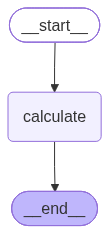

In [11]:
from IPython.display import Image, display
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [12]:
print("🧮 简单计算器")
print("=" * 40)

# 测试：加法
result = graph.invoke({
    "num1": 10,
    "num2": 5,
    "operator": "-"
})

print(f"结果：{result['result']}")

🧮 简单计算器
准备计算 10 - 5
结果：5
